**EQUILIBRIUM CONVERSION CHECKER**


In a reactor the reaction A+B gives C reaches equilibrium. Initial concentrations are [A]0 = 1.5 , [B]0  = 1.0 and [C]0 = 0 mol/L of C is formed , Kc = x/((1.5-x)(1-x)),which rearranges to the quadratic equation

Kc.x^2-(2.5Kc+1).x +1.5Kc=0

Write a program that:

(a)reads Kc using input(),prints the data type of the raw input and of the converted value , and shows a clear message (no crash) if the text is not a number pr if Kc<=0;

(b)finds a,b,c, the decriminant and both roots;

(c)selects the physically meaningful root (0<=x<=1,because B is liminting);

(d)prints equilibrium [A],[B],[C](3 decimal) and the conversion of the limiting reactant B=x/[B]0 * 100(%);

(e)classifies the conversion using if/elif/else:>=70% "High",>=40% "Moderate", otherwise "Low"

Test with Kc = 4 ,Kc = 0.5 , Kc = abc and Kc = -2

In [1]:
# Read the equilibrium constant from the user.
raw_kc = input("Enter a positive value for Kc: ")
print("Type of the raw input:", type(raw_kc))

# Convert the input text to a number. Stop safely if it is not numeric.
try:
    kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be a number. Please try again.")
else:
    print("Type of the converted value:", type(kc))

    if kc <= 0:
        print("Error: Kc must be greater than 0.")
    else:
        # For a*x^2 + b*x + c = 0:
        a = kc
        b = -(2.5 * kc + 1)
        c = 1.5 * kc

        discriminant = b**2 - 4 * a * c
        print("a =", a)
        print("b =", b)
        print("c =", c)
        print("Discriminant =", discriminant)

        # Calculate both solutions to the quadratic equation.
        root1 = (-b + discriminant**0.5) / (2 * a)
        root2 = (-b - discriminant**0.5) / (2 * a)
        print("Root 1 =", root1)
        print("Root 2 =", root2)

        # B is the limiting reactant, so its concentration cannot be negative.
        if 0 <= root1 <= 1:
            x = root1
        elif 0 <= root2 <= 1:
            x = root2
        else:
            x = None
            print("Error: no root is physically meaningful (between 0 and 1).")

        if x is not None:
            concentration_a = 1.5 - x
            concentration_b = 1.0 - x
            concentration_c = x
            conversion = (x / 1.0) * 100

            print("\nEquilibrium concentrations:")
            print(f"[A] = {concentration_a:.3f} mol/L")
            print(f"[B] = {concentration_b:.3f} mol/L")
            print(f"[C] = {concentration_c:.3f} mol/L")
            print(f"Conversion of B = {conversion:.3f}%")

            if conversion >= 70:
                category = "High"
            elif conversion >= 40:
                category = "Moderate"
            else:
                category = "Low"

            print("Conversion category:", category)

# Try entering: 4, 0.5, abc, or -2

Type of the raw input: <class 'str'>
Type of the converted value: <class 'float'>
a = 0.5
b = -2.25
c = 0.75
Discriminant = 3.5625
Root 1 = 4.1374586088176875
Root 2 = 0.36254139118231254

Equilibrium concentrations:
[A] = 1.137 mol/L
[B] = 0.637 mol/L
[C] = 0.363 mol/L
Conversion of B = 36.254%
Conversion category: Low


**BATCH REACTOR SIMULATION AND BATCH TRACKING**

    PartA.  In a batch reactor, reactant A is consumed by a first-order reaction, dC/dt = -kC .Use the Eulers method: C_new = C_old - k.C_old.deltat.Take C0 = 2.5 mol/L, k = 0.04 min^-1.

    (1)Using a for loop ,simulate 12 minutes and print a table of Time (min), Concentration (mol/L) and Conversion(%).

    (2)Using math.exp(), calculate the exact value C0e^(-kt) at 12 min and print the absolute error of the Euler result.

    (3)Using a while loop , reapeat the simulation until conversion reaches 40% or time reaches 100 min. Print the time needed and the final concentration.

    PartB.  Distillation-column sample codes such as DIST2026X9Q3 are stored as text. Write a program that reads a code, loops through each character , and prints the number of digits. Test with DIST2026X9Q3 , an empty code and ABCDEF.

In [7]:
import math

# Part A: Euler's method for 12 minutes
initial_concentration = 2.5  # mol/L
rate_constant = 0.04         # per minute
time_step = 1                # minute
concentration = initial_concentration

print("Time (min) | Concentration (mol/L) | Conversion (%)")
print("---------------------------------------------------")
print(f"{0:10d} | {concentration:22.3f} | {0:14.2f}")

# Each loop represents one minute of reaction.
for time in range(1, 13):
    concentration = concentration - rate_constant * concentration * time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{time:10d} | {concentration:22.3f} | {conversion:14.2f}")

# Compare the Euler result at 12 minutes with the exact result.
exact_concentration = initial_concentration * math.exp(-rate_constant * 12)
error = abs(exact_concentration - concentration)
print("\nExact concentration at 12 min:", f"{exact_concentration:.3f} mol/L")
print("Absolute error:", f"{error:.3f} mol/L")

# Use a while loop until conversion is 40% or time reaches 100 minutes.
concentration = initial_concentration
time = 0
conversion = 0

while conversion < 40 and time < 100:
    concentration = concentration - rate_constant * concentration * time_step
    time = time + time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100

print("\nWhile-loop result:")
print("Time needed:", time, "minutes")
print("Final concentration:", f"{concentration:.3f} mol/L")
print("Final conversion:", f"{conversion:.2f}%")

# Part B: Count the digits in a sample code.
code = input("\nEnter a distillation-column sample code: ")
digit_count = 0

for character in code:
    if character.isdigit():
        digit_count = digit_count + 1

print("Number of digits:", digit_count)

# Try DIST2026X9Q3, press Enter for an empty code, or try ABCDEF.

Time (min) | Concentration (mol/L) | Conversion (%)
---------------------------------------------------
         0 |                  2.500 |           0.00
         1 |                  2.400 |           4.00
         2 |                  2.304 |           7.84
         3 |                  2.212 |          11.53
         4 |                  2.123 |          15.07
         5 |                  2.038 |          18.46
         6 |                  1.957 |          21.72
         7 |                  1.879 |          24.86
         8 |                  1.803 |          27.86
         9 |                  1.731 |          30.75
        10 |                  1.662 |          33.52
        11 |                  1.596 |          36.18
        12 |                  1.532 |          38.73

Exact concentration at 12 min: 1.547 mol/L
Absolute error: 0.015 mol/L

While-loop result:
Time needed: 13 minutes
Final concentration: 1.471 mol/L
Final conversion: 41.18%
Number of digits: 0


**SOLVENT SCREENING AND SAMPLING SCHEDULE**

PartA.  A laboratory has n candidate solvents and wantys to test r of them together in a mixed solvent (order does not matter). Write a recursive function factorial(n)(remember the base case for 0!)and a function combination (n,r) = n!/(r!(n-r)!) that uses it. Reject invalid input (negative values , r>n). Print the number of possible mixtures for n= 9 , r = 3 ,and show the message for n=6, r=8.

PartB.  During a crystallization run, samples are taken at times = Fibonnaci numer * 4min. Write an iterative function fib_iter(n) that returns a list of the first n Fibonacci numbers, and a recursive function fib_rec(k) that returns the k-yh Fibonacci number(F0 = 0, F1 = 1). For n= 10 , check that both functions agree and print a table : Sample No.| Fibonacci tag| Sampling time(min).

In [8]:
# Part A: Count solvent mixtures using combinations.

def factorial(number):
    # 0! and 1! are both 1, so recursion stops here.
    if number == 0 or number == 1:
        return 1
    return number * factorial(number - 1)


def combination(n, r):
    # A combination is not possible if these values are invalid.
    if n < 0 or r < 0 or r > n:
        print("Invalid values: n and r must be non-negative, and r cannot be greater than n.")
        return None

    return factorial(n) // (factorial(r) * factorial(n - r))


mixtures = combination(9, 3)
print("Number of mixtures for n=9 and r=3:", mixtures)

# This example is invalid because 8 solvents cannot be chosen from 6.
combination(6, 8)


# Part B: Generate Fibonacci numbers in two different ways.

def fib_iter(n):
    # Build and return a list of the first n Fibonacci numbers.
    numbers = []
    first = 0
    second = 1

    for _ in range(n):
        numbers.append(first)
        first, second = second, first + second

    return numbers


def fib_rec(k):
    # These are the starting values of the Fibonacci sequence.
    if k == 0:
        return 0
    if k == 1:
        return 1

    return fib_rec(k - 1) + fib_rec(k - 2)


number_of_samples = 10
iterative_numbers = fib_iter(number_of_samples)
recursive_numbers = [fib_rec(index) for index in range(number_of_samples)]

print("\nDo the iterative and recursive results agree?", iterative_numbers == recursive_numbers)
print("Sample No. | Fibonacci tag | Sampling time (min)")
print("-----------------------------------------------")

for sample_number in range(1, number_of_samples + 1):
    fibonacci_tag = iterative_numbers[sample_number - 1]
    sampling_time = fibonacci_tag * 4
    print(f"{sample_number:10} | {fibonacci_tag:13} | {sampling_time:19}")

Number of mixtures for n=9 and r=3: 84
Invalid values: n and r must be non-negative, and r cannot be greater than n.

Do the iterative and recursive results agree? True
Sample No. | Fibonacci tag | Sampling time (min)
-----------------------------------------------
         1 |             0 |                   0
         2 |             1 |                   4
         3 |             1 |                   4
         4 |             2 |                   8
         5 |             3 |                  12
         6 |             5 |                  20
         7 |             8 |                  32
         8 |            13 |                  52
         9 |            21 |                  84
        10 |            34 |                 136


**KINETICS AND GAS DATA : PANDAS AND MATPLOTLIB**

Consumption of a reactant was studied in a batch reactor with two feed concentrations of catalyst. The concentration (mol/L) was recorded:

|  Time_min  |  Run1_mol_L(low catalyst)  |  Run2_mol_L(high catalyst)  |
|----------------------------------------|
| 0  | 1.50  | 1.50  |
| 10  | 1.17  | 0.96  |
| 20  | 0.91  | 0.61  |
| 30  | 0.71  | 0.39  |
| 40  | 0.55  | 0.25  |
| 50  | 0.43  | 0.16  |

(a)Create a DataFrame from t5his table . Save it as kinetics.csv(without thge index column) and as kinetics.json. Read the CSV back and print its shape and data types.

(b)Print the mean and standard deviation of Run1 and Run2 ,and state which run shows more variation .

(c)Plot both runs on one graph (time on x-axis)with title, axis labels with units, legend and grid.

(d)Ethylene gas is compressed slowly in a piston - cylinder at constant temperature:

|  Volume_L  | 1  | 2  | 3  | 4  | 5  |
|  Pressure_bar  | 5.03  | 2.52  | 1.65  | 1.26  | 1.01  |

Plot pressure vs. Volume as a scatter plot . Calculate k as the mean of P*V and draw the reference curve P = k/V on the same graph. Add title, lables with units and legend.

CSV shape: (6, 3)
CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Run 1 mean: 0.8783333333333333
Run 1 standard deviation: 0.40241355179301136
Run 2 mean: 0.645
Run 2 standard deviation: 0.5074938423271754
Run 2 shows more variation.


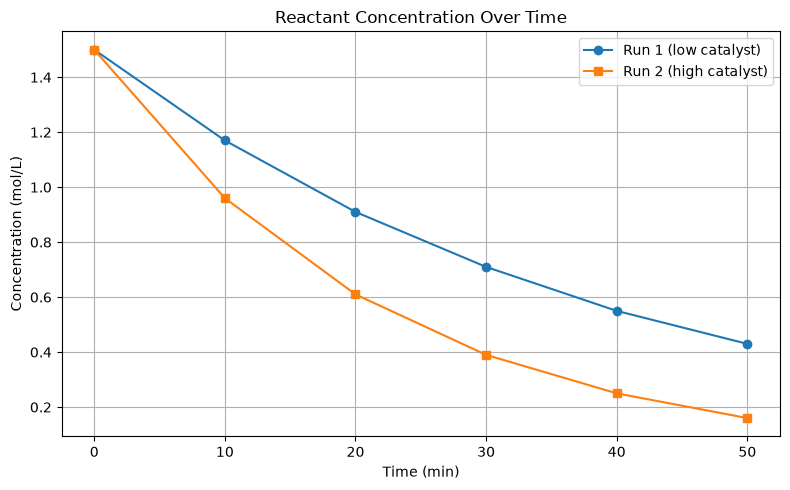


Mean P*V (k): 5.022 bar L


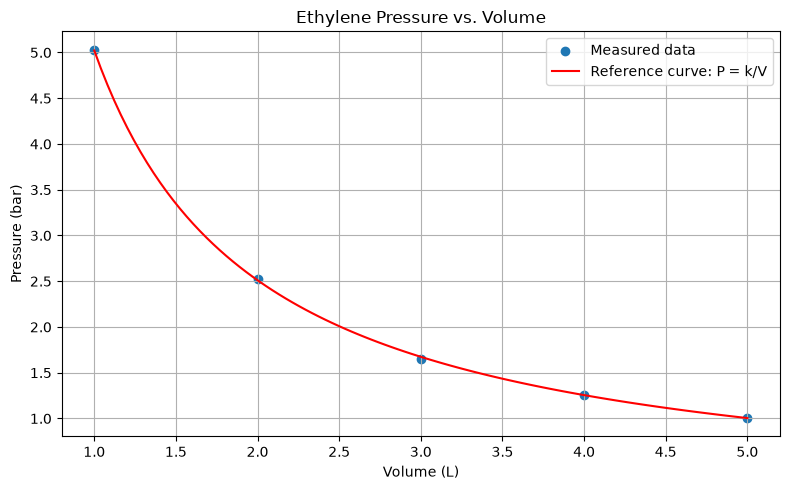

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Part A: Store the reactor measurements in a DataFrame.
kinetics_data = {
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "Run2_mol_L": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16]
}
kinetics = pd.DataFrame(kinetics_data)

# Save the data, then read the CSV back to check it.
kinetics.to_csv("kinetics.csv", index=False)
kinetics.to_json("kinetics.json", orient="records", indent=4)
kinetics_from_csv = pd.read_csv("kinetics.csv")

print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

# Compare the average concentration and standard deviation for each run.
run1_mean = kinetics["Run1_mol_L"].mean()
run1_std = kinetics["Run1_mol_L"].std()
run2_mean = kinetics["Run2_mol_L"].mean()
run2_std = kinetics["Run2_mol_L"].std()

print("\nRun 1 mean:", run1_mean)
print("Run 1 standard deviation:", run1_std)
print("Run 2 mean:", run2_mean)
print("Run 2 standard deviation:", run2_std)

if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")

# Plot both concentration runs on the same graph.
plt.figure(figsize=(8, 5))
plt.plot(kinetics["Time_min"], kinetics["Run1_mol_L"], marker="o", label="Run 1 (low catalyst)")
plt.plot(kinetics["Time_min"], kinetics["Run2_mol_L"], marker="s", label="Run 2 (high catalyst)")
plt.title("Reactant Concentration Over Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Part D: Calculate k from the pressure-volume measurements.
gas_data = {
    "Volume_L": [1, 2, 3, 4, 5],
    "Pressure_bar": [5.03, 2.52, 1.65, 1.26, 1.01]
}
gas = pd.DataFrame(gas_data)
k = (gas["Pressure_bar"] * gas["Volume_L"]).mean()
print("\nMean P*V (k):", k, "bar L")

# Draw the measured points and the reference curve P = k / V.
volume_curve = np.linspace(gas["Volume_L"].min(), gas["Volume_L"].max(), 100)
pressure_curve = k / volume_curve

plt.figure(figsize=(8, 5))
plt.scatter(gas["Volume_L"], gas["Pressure_bar"], label="Measured data")
plt.plot(volume_curve, pressure_curve, color="red", label="Reference curve: P = k/V")
plt.title("Ethylene Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()